In [21]:
from src.motivating_example import MotivatingExample
import numpy as np
from scipy.stats import norm

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

In [23]:
B = 50

res = {
    'mar': np.empty((B, 8)),
    'mar_like': np.empty((B, 8)),
    'mnar': np.empty((10, B, 8))
}

types = ['mar', 'mar_like', 'mnar']

for m in types:
    me = MotivatingExample(type=m, n=2000, d=2, B=B)
    res[m] = me.evaluate()

In [ ]:
# import pickle
# with open("results/motexp.pkl", "rb") as f:
#     res = pickle.load(f)


qs = {
    'mar': res['mar'][['qx1_gen', 'qx1_imp']],
    'mar_like': res['mar_like'][['qx1_gen', 'qx1_imp']],
    'mnar': res['mnar'][:,:,0].T
}

ticklabels = {
    'mar': ["Generation", "Imputation"],
    'mar_like': ["Generation", "Imputation"],
    'mnar': [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
}

subtitles = {
    'mar': 'MAR',
    'mar_like': 'MAR-like MNAR',
    'mnar': r'MAR with $\epsilon$-contamination of MNAR'
}

xlabels = {
    'mar': 'Method',
    'mar_like': 'Method',
    'mnar': r'$\epsilon$'
}

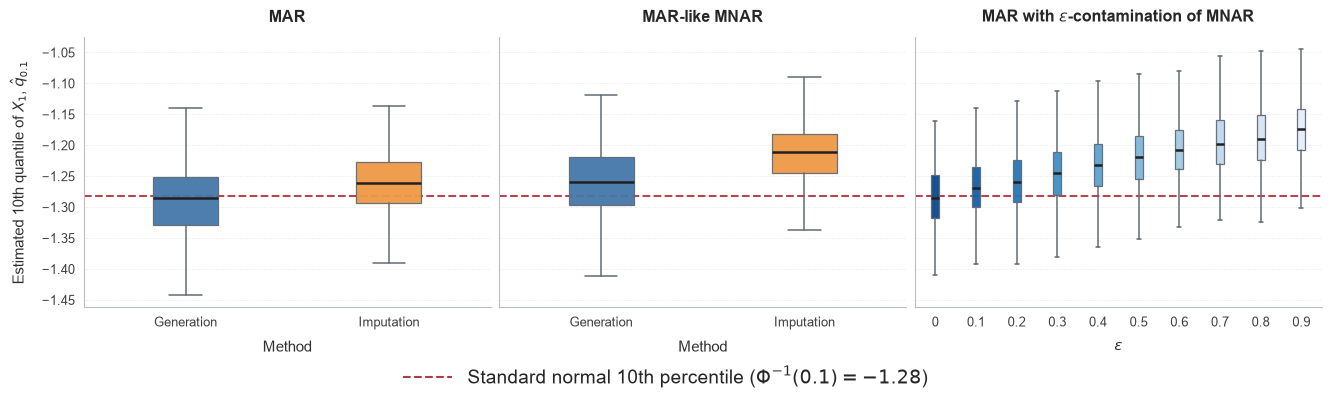

In [33]:
# --------------------------------------------------
# Global style
# --------------------------------------------------
sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.15,
    rc={
        "font.family": "sans-serif",
        "axes.titleweight": "semibold",
        "axes.labelcolor": "#303030",
        "xtick.color": "#404040",
        "ytick.color": "#404040",
        "grid.color": "#D9DEE7",
        "grid.linewidth": 0.65,
        "axes.edgecolor": "#B8BEC8",
        "axes.linewidth": 0.8,
        "savefig.dpi": 300,
    },
)

# --------------------------------------------------
# Figure setup
# --------------------------------------------------
n_types = len(types)

if n_types == 0:
    raise ValueError("types must contain at least one panel.")

fig, axes = plt.subplots(
    1,
    n_types,
    figsize=(4.4 * n_types, 4.0),
    sharey=True,
    squeeze=False,
    constrained_layout=True,
)

axes = axes.ravel()

# Theoretical 10th percentile of the standard normal
q10 = norm.ppf(0.1)

# Colors
two_box_colors = ["#4477AA", "#EE9944"]
reference_color = "#B23A48"

# Ten shades from dark blue to light blue
blue_gradient = sns.color_palette(
    "Blues", n_colors=10
)[::-1]

# --------------------------------------------------
# Draw panels
# --------------------------------------------------
for ax, type_name in zip(axes, types):

    data = qs[type_name]

    # Number of boxplots
    n_boxes = data.shape[1] if data.ndim > 1 else 1

    # Adaptive width: narrow for two boxes, suitable for ten
    box_width = min(0.32, 2.0 / n_boxes)

    bp = ax.boxplot(
        data,
        tick_labels=ticklabels[type_name],
        patch_artist=True,
        widths=box_width,
        showfliers=False,
        medianprops=dict(
            color="#202020",
            linewidth=1.8,
        ),
        whiskerprops=dict(
            color="#626B75",
            linewidth=1.1,
        ),
        capprops=dict(
            color="#626B75",
            linewidth=1.1,
        ),
        boxprops=dict(
            edgecolor="#626B75",
            linewidth=0.9,
        ),
        zorder=2,
    )

    # Choose palette based on number of boxes
    if n_boxes == 2:
        colors = two_box_colors
    elif n_boxes == 10:
        colors = blue_gradient
    else:
        colors = sns.color_palette(
            "Blues", n_colors=n_boxes + 2
        )[1:-1]

    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.95)

    # Theoretical reference line
    ax.axhline(
        q10,
        color=reference_color,
        linestyle="--",
        linewidth=1.5,
        alpha=0.95,
        zorder=1,
    )

    # Titles and labels
    ax.set_title(
        subtitles[type_name],
        fontsize=11.5,
        pad=11,
        fontweight="semibold",
    )

    ax.set_xlabel(
        xlabels[type_name],
        fontsize=10.5,
        labelpad=8,
    )

    # Grid and spines
    ax.set_axisbelow(True)
    ax.grid(axis="y", linestyle=":", alpha=0.8)
    ax.grid(axis="x", visible=False)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        axis="both",
        labelsize=9,
        length=3,
        color="#8A9099",
    )

    # Add whitespace around the boxes
    ax.margins(x=0.12)

# --------------------------------------------------
# Shared y-axis label
# --------------------------------------------------
axes[0].set_ylabel(
    r"Estimated 10th quantile of $X_1$, $\hat{q}_{0.1}$",
    fontsize=10.5,
    labelpad=10,
)

# --------------------------------------------------
# Shared legend
# --------------------------------------------------
reference_handle = Line2D(
    [0],
    [0],
    color=reference_color,
    linestyle="--",
    linewidth=1.5,
    label=fr"Standard normal 10th percentile ($\Phi^{{-1}}(0.1)={q10:.2f}$)",
)

fig.legend(
    handles=[reference_handle],
    loc="outside lower center",
    frameon=False,
    fontsize=14,
    handlelength=2.5,
)

# --------------------------------------------------
# Save figures
# --------------------------------------------------
fig.savefig(
    "motexp.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()
